In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/nlp_task_4"
folders = [
    "data/raw", "data/processed", "notebooks",
    "app", "models", "outputs", "screenshots", "report"
]
for f in folders:
    os.makedirs(f"{BASE}/{f}", exist_ok=True)

print("Done:", os.listdir(BASE))

Mounted at /content/drive
Done: ['data', 'notebooks', 'app', 'models', 'outputs', 'screenshots', 'report']


In [ ]:
import pandas as pd

BASE = "/content/drive/MyDrive/nlp_task_4"

R, W, E = "Roads / Infrastructure", "Water Supply", "Electricity"
S, H, T = "Sanitation", "Health", "Traffic"

rows = [
# ---- Roads ----
("The road in our area has been broken for months and rainwater collects every day. Please fix it urgently.", R, "Negative", "High"),
("There is a deep pothole near the school gate and children can fall into it.", R, "Negative", "High"),
("Street lights on the main road have not worked for two weeks.", R, "Negative", "Medium"),
("The new road in our colony was completed quickly and the quality is good.", R, "Positive", "Low"),
("The bridge near the market has cracks and looks dangerous for vehicles.", R, "Negative", "Urgent"),
("Footpath is blocked by broken tiles and old people cannot walk safely.", R, "Negative", "Medium"),
("Please repair the speed breaker on our street, it is damaged.", R, "Neutral", "Low"),
("Construction work on the road has been left half finished for a month.", R, "Negative", "Medium"),
("An open manhole on the road is a serious danger at night.", R, "Negative", "Urgent"),
("Thank you for repairing the road outside our mosque.", R, "Positive", "Low"),
# ---- Water ----
("There is no water supply in our area for three days.", W, "Negative", "High"),
("The tap water is dirty and has a bad smell.", W, "Negative", "High"),
("Water pressure is very low in the morning.", W, "Negative", "Medium"),
("A main pipeline is leaking near the park and water is wasted all day.", W, "Negative", "Medium"),
("Water supply timing was changed, please inform residents in advance.", W, "Neutral", "Low"),
("Many children in our street fell sick after drinking contaminated water.", W, "Negative", "Urgent"),
("The new water filter plant in our town is working well.", W, "Positive", "Low"),
("We pay the water bill regularly but receive water only twice a week.", W, "Negative", "Medium"),
("Please clean the water tank of our neighborhood, it has not been cleaned for months.", W, "Negative", "Medium"),
("The tanker arrived on time today and the supply was good.", W, "Positive", "Low"),
# ---- Electricity ----
("No electricity since morning.", E, "Negative", "Medium"),
("Load shedding is more than eight hours daily in our village.", E, "Negative", "High"),
("A live wire has fallen on the street near the children's playground.", E, "Negative", "Urgent"),
("The transformer in our street keeps making loud noises and sparks.", E, "Negative", "Urgent"),
("My electricity bill is double this month although usage is the same.", E, "Negative", "Medium"),
("Voltage fluctuation damaged our fridge again.", E, "Negative", "High"),
("The staff fixed the power fault quickly, thank you.", E, "Positive", "Low"),
("Please install a new electricity meter at our new house.", E, "Neutral", "Low"),
("Street power poles are leaning and may fall in heavy wind.", E, "Negative", "High"),
("Power went off for a short time yesterday evening.", E, "Neutral", "Low"),
# ---- Sanitation ----
("Garbage is not collected from our street for a week.", S, "Negative", "High"),
("The sewer line is blocked and dirty water is flowing on the road.", S, "Negative", "High"),
("Please place more dustbins near the market.", S, "Neutral", "Low"),
("Heaps of waste near the school are causing mosquitoes.", S, "Negative", "High"),
("The sweeper comes regularly and our street is now clean.", S, "Positive", "Low"),
("Open drain near our house smells terrible all day.", S, "Negative", "Medium"),
("Waste is burned in the open nearby and the smoke is hard to breathe.", S, "Negative", "High"),
("The sewerage water entered our homes after rain.", S, "Negative", "Urgent"),
("Please clean the drain before the rainy season starts.", S, "Neutral", "Medium"),
("Public toilets in the bus stand are very dirty.", S, "Negative", "Medium"),
# ---- Health ----
("The hospital staff was helpful but the waiting time was too long.", H, "Neutral", "Medium"),
("No doctor was available in the emergency ward last night.", H, "Negative", "Urgent"),
("Medicines are not available at the government dispensary.", H, "Negative", "High"),
("The nurse behaved rudely with my mother.", H, "Negative", "Medium"),
("The new health center near our village is excellent and the doctors are kind.", H, "Positive", "Low"),
("Dengue cases are increasing in our area and no spray has been done.", H, "Negative", "High"),
("Ambulance took more than an hour to reach us.", H, "Negative", "Urgent"),
("Please start a vaccination camp in our locality.", H, "Neutral", "Low"),
("The lab test results were delayed by five days.", H, "Negative", "Medium"),
("Hospital washrooms are dirty and patients are suffering.", H, "Negative", "Medium"),
# ---- Traffic ----
("Traffic signal at the main chowk has not worked for days.", T, "Negative", "High"),
("Heavy traffic jam every evening near the university.", T, "Negative", "Medium"),
("Vehicles are parked wrongly on the road and block the way.", T, "Negative", "Medium"),
("Rickshaws drive in the wrong direction and cause accidents.", T, "Negative", "High"),
("Please add a traffic warden at this busy intersection.", T, "Neutral", "Low"),
("Three accidents happened this week at the same turn, please install a signal.", T, "Negative", "Urgent"),
("Traffic police managed the rush very well today.", T, "Positive", "Low"),
("Heavy trucks enter the city during the day and block roads.", T, "Negative", "High"),
("There is no zebra crossing near the school.", T, "Negative", "Medium"),
("The new one-way system has reduced the jam on our road.", T, "Positive", "Low"),
]

df = pd.DataFrame(rows, columns=["text", "category", "sentiment", "priority"])
df["source"] = "manual"          # ye sample haath se likhe hue hain
df.to_csv(f"{BASE}/data/raw/feedback_raw.csv", index=False)

print(df.shape)
print(df["category"].value_counts())

(60, 5)
category
Roads / Infrastructure    10
Water Supply              10
Electricity               10
Sanitation                10
Health                    10
Traffic                   10
Name: count, dtype: int64


In [ ]:
import pandas as pd

BASE = "/content/drive/MyDrive/nlp_task_4"
R, W, E = "Roads / Infrastructure", "Water Supply", "Electricity"
S, H, T = "Sanitation", "Health", "Traffic"

rows2 = [
# ---- Roads ----
("Road is broken and water is standing.", R, "Negative", "Medium"),
("Potholes everywhere on the road to the hospital.", R, "Negative", "High"),
("The street near our house has no lights at night and feels unsafe.", R, "Negative", "Medium"),
("Please repair the damaged road before the rainy season.", R, "Neutral", "Medium"),
("A big crack has appeared in the road near the canal bridge.", R, "Negative", "High"),
("Road repair work was done properly and on time.", R, "Positive", "Low"),
("The service road is full of dust and stones.", R, "Negative", "Low"),
("A road collapse near the underpass may cause a major accident.", R, "Negative", "Urgent"),
("Please build a speed breaker near the primary school.", R, "Neutral", "Low"),
("Broken road.", R, "Negative", "Medium"),
# ---- Water ----
("No water today.", W, "Negative", "Medium"),
("Water is coming mixed with mud in our taps.", W, "Negative", "High"),
("The water supply was restored quickly after our complaint.", W, "Positive", "Low"),
("There is a water leakage on the main road and the pipeline is broken.", W, "Negative", "Medium"),
("Our area gets water only at midnight, which is hard for families.", W, "Negative", "Medium"),
("Please provide a water tanker for our street this week.", W, "Neutral", "Medium"),
("People are standing in long queues to get drinking water.", W, "Negative", "High"),
("Chlorine is not added to the water and people are getting stomach infections.", W, "Negative", "Urgent"),
("The water meter reading seems incorrect.", W, "Neutral", "Low"),
("Water supply has improved a lot in our block recently.", W, "Positive", "Low"),
# ---- Electricity ----
("Power outage again!", E, "Negative", "Medium"),
("The street light pole is giving electric shocks when touched.", E, "Negative", "Urgent"),
("Electricity theft by hooks in our area is causing low voltage.", E, "Negative", "High"),
("Please send a lineman to check the faulty wire.", E, "Neutral", "Medium"),
("The new smart meter works fine and the bill is correct.", E, "Positive", "Low"),
("No light at night and children cannot study.", E, "Negative", "High"),
("The electricity office staff solved my complaint in one day.", E, "Positive", "Low"),
("Frequent tripping of electricity during the day.", E, "Negative", "Medium"),
("A damaged electric pole on the road is leaning toward houses.", E, "Negative", "Urgent"),
("Electricity bill was delivered late this month.", E, "Neutral", "Low"),
# ---- Sanitation ----
("Garbage is not collected.", S, "Negative", "Medium"),
("Rubbish is piled up near the water tank and spreading disease.", S, "Negative", "High"),
("The sewer cover is missing and dirty water is overflowing.", S, "Negative", "High"),
("The municipal team cleaned the drain today, thank you.", S, "Positive", "Low"),
("Please clean the vacant plot where people throw waste.", S, "Neutral", "Medium"),
("Stray dogs gather around garbage near our street.", S, "Negative", "Medium"),
("Foul smell from the dumping point near the houses.", S, "Negative", "High"),
("Choked gutters flooded the whole street after rain.", S, "Negative", "High"),
("Request to arrange a weekly cleaning drive in our colony.", S, "Neutral", "Low"),
("Dead animal on the roadside has not been removed for two days.", S, "Negative", "High"),
# ---- Health ----
("Hospital staff was rude.", H, "Negative", "Medium"),
("No bed was available for the patient in the government hospital.", H, "Negative", "Urgent"),
("The doctor listened carefully and treated my child well.", H, "Positive", "Low"),
("Free medicines are not given to poor patients.", H, "Negative", "High"),
("The clinic opens late and closes early.", H, "Negative", "Medium"),
("Please send a mobile health unit to our village.", H, "Neutral", "Medium"),
("X-ray machine at the hospital has been out of order for a week.", H, "Negative", "High"),
("Long queues at the OPD, we waited four hours.", H, "Negative", "Medium"),
("Children in our area have fever and cough, a medical team is needed urgently.", H, "Negative", "Urgent"),
("The hospital environment is clean and the staff is polite.", H, "Positive", "Low"),
# ---- Traffic ----
("Traffic jam.", T, "Negative", "Medium"),
("Cars are parked in two rows outside the market and the road is blocked.", T, "Negative", "Medium"),
("Traffic signal is red for too long at the main intersection.", T, "Negative", "Low"),
("Please place traffic wardens near the school during pick-up time.", T, "Neutral", "Medium"),
("Motorbikes drive on the footpath and put pedestrians at risk.", T, "Negative", "High"),
("Many accidents happen at the highway entrance because of overspeeding.", T, "Negative", "Urgent"),
("Traffic flow is smooth after the new signal was installed.", T, "Positive", "Low"),
("Buses stop in the middle of the road and cause jams.", T, "Negative", "Medium"),
("No road signs near the sharp turn on the bypass.", T, "Negative", "High"),
("Heavy traffic jam and broken road near the bridge.", T, "Negative", "Medium"),
]

df2 = pd.DataFrame(rows2, columns=["text", "category", "sentiment", "priority"])
df2["source"] = "manual"

df1 = pd.read_csv(f"{BASE}/data/raw/feedback_raw.csv")
df = pd.concat([df1, df2], ignore_index=True).drop_duplicates(subset="text")
df.to_csv(f"{BASE}/data/raw/feedback_raw.csv", index=False)

print(df.shape)
print(df["category"].value_counts())

(120, 5)
category
Roads / Infrastructure    20
Water Supply              20
Electricity               20
Sanitation                20
Health                    20
Traffic                   20
Name: count, dtype: int64


In [ ]:
import pandas as pd

BASE = "/content/drive/MyDrive/nlp_task_4"
extra = pd.read_csv(f"{BASE}/data/raw/feedback_manual_extra.csv")

print(extra.shape)
print(extra["category"].value_counts())

(90, 4)
category
Roads / Infrastructure    15
Water Supply              15
Electricity               15
Sanitation                15
Health                    15
Traffic                   15
Name: count, dtype: int64


In [ ]:
import pandas as pd, re, os
from sklearn.model_selection import train_test_split

BASE = "/content/drive/MyDrive/nlp_task_4"
raw   = pd.read_csv(f"{BASE}/data/raw/feedback_raw.csv")
extra = pd.read_csv(f"{BASE}/data/raw/feedback_manual_extra.csv")

print("raw:", raw.shape, list(raw.columns))
print("extra:", extra.shape, list(extra.columns))

# 1. Merge
cols = ["text", "category", "sentiment", "priority"]
df = pd.concat([raw[cols], extra[cols]], ignore_index=True)
print("merged:", df.shape)

# 2. Cleaning
def clean(t):
    return re.sub(r"\s+", " ", str(t).strip())

df = df.dropna(subset=["text"])
df["text"] = df["text"].apply(clean)
for c in ["category", "sentiment", "priority"]:
    df[c] = df[c].astype(str).str.strip()
df = df[df["text"] != ""]

# 3. Duplicates
df["key"] = df["text"].str.lower()
before = len(df)
df = df.drop_duplicates(subset="key").drop(columns="key").reset_index(drop=True)
print("duplicates removed:", before - len(df))
print("final:", df.shape)

# 4. Label check
print(df["category"].value_counts())
print(df["sentiment"].value_counts())
print(df["priority"].value_counts())

# 5. Split 70/15/15
train, temp = train_test_split(df, test_size=0.30, random_state=42, stratify=df["category"])
val, test   = train_test_split(temp, test_size=0.50, random_state=42, stratify=temp["category"])
print("train/val/test:", len(train), len(val), len(test))

# 6. Save
out = f"{BASE}/data/processed"
os.makedirs(out, exist_ok=True)
df.to_csv(f"{out}/feedback_clean.csv", index=False)
train.to_csv(f"{out}/train.csv", index=False)
val.to_csv(f"{out}/val.csv", index=False)
test.to_csv(f"{out}/test.csv", index=False)
print("saved to", out)

raw: (120, 5) ['text', 'category', 'sentiment', 'priority', 'source']
extra: (90, 4) ['text', 'category', 'sentiment', 'priority']
merged: (210, 4)
duplicates removed: 0
final: (210, 4)
category
Roads / Infrastructure    35
Water Supply              35
Electricity               35
Sanitation                35
Health                    35
Traffic                   35
Name: count, dtype: int64
sentiment
Negative    147
Neutral      33
Positive     30
Name: count, dtype: int64
priority
Medium    74
Low       56
High      55
Urgent    25
Name: count, dtype: int64
train/val/test: 147 31 32
saved to /content/drive/MyDrive/nlp_task_4/data/processed


In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

BASE = "/content/drive/MyDrive/nlp_task_4"
P = f"{BASE}/data/processed"
train = pd.read_csv(f"{P}/train.csv")
val   = pd.read_csv(f"{P}/val.csv")
test  = pd.read_csv(f"{P}/test.csv")

def make_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ])

models = {}
for target in ["category", "sentiment", "priority"]:
    m = make_model()
    m.fit(train["text"], train[target])
    models[target] = m

    pv = m.predict(val["text"])
    print(f"\n===== {target.upper()} (validation) =====")
    print("accuracy :", round(accuracy_score(val[target], pv), 3))
    print("macro F1 :", round(f1_score(val[target], pv, average="macro"), 3))

# Test par sirf category ki detail (final report ke liye)
pt = models["category"].predict(test["text"])
print("\n===== CATEGORY (test) =====")
print(classification_report(test["category"], pt, zero_division=0))
labels = sorted(train["category"].unique())
print(pd.DataFrame(confusion_matrix(test["category"], pt, labels=labels), index=labels, columns=labels))


===== CATEGORY (validation) =====
accuracy : 0.71
macro F1 : 0.71

===== SENTIMENT (validation) =====
accuracy : 0.903
macro F1 : 0.867

===== PRIORITY (validation) =====
accuracy : 0.516
macro F1 : 0.469

===== CATEGORY (test) =====
                        precision    recall  f1-score   support

           Electricity       1.00      0.80      0.89         5
                Health       1.00      1.00      1.00         5
Roads / Infrastructure       0.80      0.67      0.73         6
            Sanitation       0.75      0.60      0.67         5
               Traffic       0.71      0.83      0.77         6
          Water Supply       0.71      1.00      0.83         5

              accuracy                           0.81        32
             macro avg       0.83      0.82      0.81        32
          weighted avg       0.83      0.81      0.81        32

                        Electricity  Health  Roads / Infrastructure  \
Electricity                       4       0        

In [ ]:
pv = models["category"].predict(val["text"])
errs = val.assign(pred=pv)
errs = errs[errs["category"] != errs["pred"]]
print("VALIDATION category errors:", len(errs))
print(errs[["text", "category", "pred"]].to_string())

pt = models["category"].predict(test["text"])
errs_t = test.assign(pred=pt)
errs_t = errs_t[errs_t["category"] != errs_t["pred"]]
print("\nTEST category errors:", len(errs_t))
print(errs_t[["text", "category", "pred"]].to_string())

VALIDATION category errors: 9
                                                                         text                category                    pred
1                    Illegal parking fees are charged near the hospital gate.                 Traffic                  Health
5              Rubbish is piled up near the water tank and spreading disease.              Sanitation            Water Supply
8                            The sewerage water entered our homes after rain.              Sanitation            Water Supply
14                                      Drivers do not follow the lane rules.                 Traffic              Sanitation
15                   The sweeper comes regularly and our street is now clean.              Sanitation                  Health
16                            The lab test results were delayed by five days.                  Health              Sanitation
21                         Open dumping near the river is polluting the area.           

In [ ]:
import pandas as pd, numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, make_union
from sklearn.model_selection import StratifiedKFold, cross_validate

BASE = "/content/drive/MyDrive/nlp_task_4"
df = pd.read_csv(f"{BASE}/data/processed/feedback_clean.csv")

word = lambda: TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
char = lambda: TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)

candidates = {
    "word + LogReg (baseline)": Pipeline([("f", word()), ("c", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "char + LogReg":            Pipeline([("f", char()), ("c", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "word+char + LogReg":       Pipeline([("f", make_union(word(), char())), ("c", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "word+char + LinearSVC":    Pipeline([("f", make_union(word(), char())), ("c", LinearSVC(class_weight="balanced"))]),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for target in ["category", "sentiment", "priority"]:
    for name, model in candidates.items():
        cv = cross_validate(model, df["text"], df[target], cv=skf,
                            scoring=["accuracy", "f1_macro"])
        rows.append({
            "target": target, "model": name,
            "acc": round(cv["test_accuracy"].mean(), 3),
            "acc_std": round(cv["test_accuracy"].std(), 3),
            "macro_f1": round(cv["test_f1_macro"].mean(), 3),
        })

res = pd.DataFrame(rows)
print(res.to_string(index=False))
res.to_csv(f"{BASE}/data/processed/cv_results.csv", index=False)

   target                    model   acc  acc_std  macro_f1
 category word + LogReg (baseline) 0.676    0.036     0.676
 category            char + LogReg 0.800    0.061     0.794
 category       word+char + LogReg 0.748    0.063     0.744
 category    word+char + LinearSVC 0.757    0.074     0.755
sentiment word + LogReg (baseline) 0.890    0.056     0.815
sentiment            char + LogReg 0.857    0.064     0.749
sentiment       word+char + LogReg 0.895    0.044     0.825
sentiment    word+char + LinearSVC 0.881    0.062     0.788
 priority word + LogReg (baseline) 0.486    0.096     0.469
 priority            char + LogReg 0.562    0.086     0.564
 priority       word+char + LogReg 0.519    0.096     0.517
 priority    word+char + LinearSVC 0.500    0.092     0.497


In [ ]:
import pandas as pd, joblib, os
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, make_union

BASE = "/content/drive/MyDrive/nlp_task_4"
df = pd.read_csv(f"{BASE}/data/processed/feedback_clean.csv")

word = lambda: TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
char = lambda: TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)
lr   = lambda: LogisticRegression(max_iter=2000, class_weight="balanced")

final = {
    "category":  Pipeline([("f", char()), ("c", lr())]),
    "sentiment": Pipeline([("f", make_union(word(), char())), ("c", lr())]),
    "priority":  Pipeline([("f", char()), ("c", lr())]),
}

os.makedirs(f"{BASE}/models", exist_ok=True)
for target, model in final.items():
    model.fit(df["text"], df[target])
    joblib.dump(model, f"{BASE}/models/{target}_model.joblib")
print("models saved:", os.listdir(f"{BASE}/models"))

def predict_feedback(text):
    out = {}
    for target in ["category", "sentiment", "priority"]:
        m = joblib.load(f"{BASE}/models/{target}_model.joblib")
        probs = m.predict_proba([text])[0]
        out[target] = {"label": m.classes_[probs.argmax()],
                       "confidence": round(float(probs.max()), 2)}
    return out

tests = [
    "The transformer in our street keeps making loud noises and sparks.",
    "There is no water supply in our area for three days.",
    "Garbage has not been collected for a week and the smell is unbearable.",
    "The new hospital staff were very helpful and polite.",
]
for t in tests:
    print("\n", t)
    print(predict_feedback(t))

models saved: ['category_model.joblib', 'sentiment_model.joblib', 'priority_model.joblib']

 The transformer in our street keeps making loud noises and sparks.
{'category': {'label': 'Electricity', 'confidence': 0.38}, 'sentiment': {'label': 'Negative', 'confidence': 0.69}, 'priority': {'label': 'Urgent', 'confidence': 0.55}}

 There is no water supply in our area for three days.
{'category': {'label': 'Water Supply', 'confidence': 0.59}, 'sentiment': {'label': 'Negative', 'confidence': 0.75}, 'priority': {'label': 'High', 'confidence': 0.51}}

 Garbage has not been collected for a week and the smell is unbearable.
{'category': {'label': 'Sanitation', 'confidence': 0.41}, 'sentiment': {'label': 'Negative', 'confidence': 0.79}, 'priority': {'label': 'High', 'confidence': 0.4}}

 The new hospital staff were very helpful and polite.
{'category': {'label': 'Health', 'confidence': 0.45}, 'sentiment': {'label': 'Positive', 'confidence': 0.66}, 'priority': {'label': 'Low', 'confidence': 0.38}

In [ ]:
def predict_feedback(text, threshold=0.35):
    out = {}
    for target in ["category", "sentiment", "priority"]:
        m = joblib.load(f"{BASE}/models/{target}_model.joblib")
        probs = m.predict_proba([text])[0]
        out[target] = {"label": m.classes_[probs.argmax()],
                       "confidence": round(float(probs.max()), 2)}

    flags = []
    if out["category"]["confidence"] < threshold:
        flags.append("Low category confidence")
    if out["priority"]["label"] == "Urgent":
        flags.append("Urgent: human review required")
    out["needs_manual_review"] = bool(flags)
    out["review_reason"] = flags
    return out

for t in [
    "The transformer in our street keeps making loud noises and sparks.",
    "Something is wrong near the market.",
]:
    print("\n", t)
    print(predict_feedback(t))


 The transformer in our street keeps making loud noises and sparks.
{'category': {'label': 'Electricity', 'confidence': 0.38}, 'sentiment': {'label': 'Negative', 'confidence': 0.69}, 'priority': {'label': 'Urgent', 'confidence': 0.55}, 'needs_manual_review': True, 'review_reason': ['Urgent: human review required']}

 Something is wrong near the market.
{'category': {'label': 'Sanitation', 'confidence': 0.24}, 'sentiment': {'label': 'Negative', 'confidence': 0.57}, 'priority': {'label': 'Low', 'confidence': 0.28}, 'needs_manual_review': True, 'review_reason': ['Low category confidence']}


In [ ]:
!pip -q install gradio

import gradio as gr, joblib

BASE = "/content/drive/MyDrive/nlp_task_4"
MODELS = {t: joblib.load(f"{BASE}/models/{t}_model.joblib")
          for t in ["category", "sentiment", "priority"]}

def analyze(text, threshold=0.35):
    if not text or not text.strip():
        return "Please enter some feedback.", "", "", ""
    res = {}
    for t, m in MODELS.items():
        p = m.predict_proba([text])[0]
        res[t] = (m.classes_[p.argmax()], float(p.max()))

    flags = []
    if res["category"][1] < threshold:
        flags.append("low category confidence")
    if res["priority"][0] == "Urgent":
        flags.append("Urgent priority")
    review = "Needs manual review (" + ", ".join(flags) + ")" if flags else "OK, no review flag"

    fmt = lambda t: f"{res[t][0]} (score {res[t][1]:.2f})"
    return fmt("category"), fmt("sentiment"), fmt("priority"), review

demo = gr.Interface(
    fn=analyze,
    inputs=gr.Textbox(lines=3, label="Citizen feedback"),
    outputs=[gr.Textbox(label="Category"),
             gr.Textbox(label="Sentiment"),
             gr.Textbox(label="Priority (indicative)"),
             gr.Textbox(label="Review flag")],
    examples=[["There is no water supply in our area for three days."],
              ["The transformer in our street keeps making loud noises and sparks."],
              ["The new hospital staff were very helpful and polite."]],
    title="Citizen Feedback Classifier",
    description="Prototype trained on 210 synthetic samples. Scores are relative, not certainty.",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e4e422a6dc5a9b4a6c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Citizen Feedback Classifier

Classifies citizen feedback into Category (6 classes), Sentiment (3) and Priority (4).

## Data
- data/raw/feedback_raw.csv (120 samples)
- data/raw/feedback_manual_extra.csv (90 samples)
- data/processed/: feedback_clean.csv, train.csv, val.csv, test.csv, cv_results.csv
- Source: synthetic, hand-reviewed feedback samples created with AI assistance.

## Method
TF-IDF (word and char n-grams) + Logistic Regression, 5-fold stratified CV.

## Results (5-fold CV, 210 samples)
- Category: accuracy 0.800, macro F1 0.794
- Sentiment: accuracy 0.895, macro F1 0.825
- Priority: accuracy 0.562, macro F1 0.564 (indicative only)

## How to run
1. Mount Google Drive and set BASE = "/content/drive/MyDrive/nlp_task_4".
2. Run the notebook cells from top to bottom.
3. The last cell launches the Gradio demo.

## Limitations
Small synthetic English dataset; no Roman Urdu; probabilities not calibrated.
Urgent or low-confidence predictions need manual review.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd, re, os, joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

BASE = "/content/drive/MyDrive/nlp_task_4"
RAW = f"{BASE}/data/raw"
cols = ["text", "category", "sentiment", "priority"]
files = ["feedback_raw.csv", "feedback_manual_extra.csv", "feedback_extra_part3.csv"]

# 1. Merge (raw files ko haath nahi lagate)
parts = []
for f in files:
    d = pd.read_csv(f"{RAW}/{f}")
    print(f, d.shape)
    parts.append(d[cols])
df = pd.concat(parts, ignore_index=True)
print("merged:", df.shape)

# 2. Missing values
print("missing:\n", df.isna().sum())
df = df.dropna(subset=cols).reset_index(drop=True)

# 3. Cleaning: CNIC, URL, phone number, extra spaces
CNIC  = re.compile(r"\b\d{5}-\d{7}-\d\b")
URL   = re.compile(r"(https?://\S+|www\.\S+)")
PHONE = re.compile(r"\+?\d[\d\-\s]{8,}\d")

def clean(t):
    t = str(t)
    t = CNIC.sub(" ", t)
    t = URL.sub(" ", t)
    t = PHONE.sub(" ", t)
    return re.sub(r"\s+", " ", t).strip()

before = df["text"].copy()
df["text"] = df["text"].apply(clean)
print("texts changed by cleaning (URL/phone/CNIC/spaces):", (before != df["text"]).sum())
df = df[df["text"] != ""].reset_index(drop=True)
for c in ["category", "sentiment", "priority"]:
    df[c] = df[c].astype(str).str.strip()

# 4. Exact duplicates (punctuation aur case ignore karke)
df["key"] = df["text"].str.lower().str.replace(r"[^\w\s]", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
n0 = len(df)
df = df.drop_duplicates(subset="key").reset_index(drop=True)
print("exact duplicates removed:", n0 - len(df))

# 5. Near-duplicates (TF-IDF similarity >= 0.9, same category)
sim = cosine_similarity(TfidfVectorizer().fit_transform(df["key"]))
cats = df["category"].values
drop = set()
for i in range(len(df)):
    if i in drop:
        continue
    for j in range(i + 1, len(df)):
        if j not in drop and sim[i, j] >= 0.9 and cats[i] == cats[j]:
            drop.add(j)
            print("near-duplicate removed:", df.loc[j, "text"], "<->", df.loc[i, "text"])
df = df.drop(index=list(drop)).drop(columns="key").reset_index(drop=True)
print("near-duplicates removed:", len(drop))
print("final:", df.shape)

# 6. Tokenization example (TfidfVectorizer ye andar khud karta hai)
print("token example:", re.findall(r"\w+", df.loc[0, "text"].lower()))

# 7. Label encoding (assignment ke IDs: sentiment 0/1/2, priority 0/1/2/3)
cat_order  = ["Roads / Infrastructure", "Water Supply", "Electricity", "Sanitation", "Health", "Traffic"]
sent_order = ["Negative", "Neutral", "Positive"]
prio_order = ["Low", "Medium", "High", "Urgent"]
maps = {
    "category":  {k: i for i, k in enumerate(cat_order)},
    "sentiment": {k: i for i, k in enumerate(sent_order)},
    "priority":  {k: i for i, k in enumerate(prio_order)},
}
for c, m in maps.items():
    unknown = set(df[c]) - set(m)
    assert not unknown, f"Unknown labels in {c}: {unknown}"
    df[c + "_id"] = df[c].map(m)

print(df["category"].value_counts())
print(df["sentiment"].value_counts())
print(df["priority"].value_counts())

# 8. Split 70/15/15 (category ke hisaab se balanced)
train, temp = train_test_split(df, test_size=0.30, random_state=42, stratify=df["category"])
val, test   = train_test_split(temp, test_size=0.50, random_state=42, stratify=temp["category"])
print("train/val/test:", len(train), len(val), len(test))

# 9. Save
out = f"{BASE}/data/processed"
os.makedirs(out, exist_ok=True)
os.makedirs(f"{BASE}/models", exist_ok=True)
df.to_csv(f"{out}/feedback_clean.csv", index=False)
train.to_csv(f"{out}/train.csv", index=False)
val.to_csv(f"{out}/val.csv", index=False)
test.to_csv(f"{out}/test.csv", index=False)

rows = [(t, lbl, i) for t, m in maps.items() for lbl, i in m.items()]
pd.DataFrame(rows, columns=["task", "label", "id"]).to_csv(f"{BASE}/data/labels.csv", index=False)
joblib.dump(maps, f"{BASE}/models/label_encoder.pkl")
print("saved: processed files, data/labels.csv, models/label_encoder.pkl")

feedback_raw.csv (120, 5)
feedback_manual_extra.csv (90, 4)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/nlp_task_4/data/raw/feedback_extra_part3.csv'

In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/nlp_task_4/data/raw"))

['feedback_raw.csv', 'feedback_manual_extra.csv', 'feedback_extra_part3.csv']


In [ ]:
import pandas as pd, re, os, joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

BASE = "/content/drive/MyDrive/nlp_task_4"
RAW = f"{BASE}/data/raw"
cols = ["text", "category", "sentiment", "priority"]
files = ["feedback_raw.csv", "feedback_manual_extra.csv", "feedback_extra_part3.csv"]

# 1. Merge
parts = []
for f in files:
    d = pd.read_csv(f"{RAW}/{f}")
    print(f, d.shape)
    parts.append(d[cols])
df = pd.concat(parts, ignore_index=True)
print("merged:", df.shape)

# 2. Missing values
print("missing:\n", df.isna().sum())
df = df.dropna(subset=cols).reset_index(drop=True)

# 3. Cleaning
CNIC  = re.compile(r"\b\d{5}-\d{7}-\d\b")
URL   = re.compile(r"(https?://\S+|www\.\S+)")
PHONE = re.compile(r"\+?\d[\d\-\s]{8,}\d")

def clean(t):
    t = str(t)
    t = CNIC.sub(" ", t)
    t = URL.sub(" ", t)
    t = PHONE.sub(" ", t)
    return re.sub(r"\s+", " ", t).strip()

before = df["text"].copy()
df["text"] = df["text"].apply(clean)
print("texts changed by cleaning:", (before != df["text"]).sum())
df = df[df["text"] != ""].reset_index(drop=True)
for c in ["category", "sentiment", "priority"]:
    df[c] = df[c].astype(str).str.strip()

# 4. Exact duplicates
df["key"] = df["text"].str.lower().str.replace(r"[^\w\s]", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
n0 = len(df)
df = df.drop_duplicates(subset="key").reset_index(drop=True)
print("exact duplicates removed:", n0 - len(df))

# 5. Near-duplicates
sim = cosine_similarity(TfidfVectorizer().fit_transform(df["key"]))
cats = df["category"].values
drop = set()
for i in range(len(df)):
    if i in drop:
        continue
    for j in range(i + 1, len(df)):
        if j not in drop and sim[i, j] >= 0.9 and cats[i] == cats[j]:
            drop.add(j)
            print("near-duplicate removed:", df.loc[j, "text"], "<->", df.loc[i, "text"])
df = df.drop(index=list(drop)).drop(columns="key").reset_index(drop=True)
print("near-duplicates removed:", len(drop))
print("final:", df.shape)

# 6. Tokenization example
print("token example:", re.findall(r"\w+", df.loc[0, "text"].lower()))

# 7. Label encoding
cat_order  = ["Roads / Infrastructure", "Water Supply", "Electricity", "Sanitation", "Health", "Traffic"]
sent_order = ["Negative", "Neutral", "Positive"]
prio_order = ["Low", "Medium", "High", "Urgent"]
maps = {
    "category":  {k: i for i, k in enumerate(cat_order)},
    "sentiment": {k: i for i, k in enumerate(sent_order)},
    "priority":  {k: i for i, k in enumerate(prio_order)},
}
for c, m in maps.items():
    unknown = set(df[c]) - set(m)
    assert not unknown, f"Unknown labels in {c}: {unknown}"
    df[c + "_id"] = df[c].map(m)

print(df["category"].value_counts())
print(df["sentiment"].value_counts())
print(df["priority"].value_counts())

# 8. Split 70/15/15
train, temp = train_test_split(df, test_size=0.30, random_state=42, stratify=df["category"])
val, test   = train_test_split(temp, test_size=0.50, random_state=42, stratify=temp["category"])
print("train/val/test:", len(train), len(val), len(test))

# 9. Save
out = f"{BASE}/data/processed"
os.makedirs(out, exist_ok=True)
os.makedirs(f"{BASE}/models", exist_ok=True)
df.to_csv(f"{out}/feedback_clean.csv", index=False)
train.to_csv(f"{out}/train.csv", index=False)
val.to_csv(f"{out}/val.csv", index=False)
test.to_csv(f"{out}/test.csv", index=False)

rows = [(t, lbl, i) for t, m in maps.items() for lbl, i in m.items()]
pd.DataFrame(rows, columns=["task", "label", "id"]).to_csv(f"{BASE}/data/labels.csv", index=False)
joblib.dump(maps, f"{BASE}/models/label_encoder.pkl")
print("saved: processed files, data/labels.csv, models/label_encoder.pkl")

feedback_raw.csv (120, 5)
feedback_manual_extra.csv (90, 4)
feedback_extra_part3.csv (300, 4)
merged: (510, 4)
missing:
 text         0
category     0
sentiment    0
priority     0
dtype: int64
texts changed by cleaning: 0
exact duplicates removed: 0
near-duplicates removed: 0
final: (510, 4)
token example: ['the', 'road', 'in', 'our', 'area', 'has', 'been', 'broken', 'for', 'months', 'and', 'rainwater', 'collects', 'every', 'day', 'please', 'fix', 'it', 'urgently']
category
Roads / Infrastructure    85
Water Supply              85
Electricity               85
Sanitation                85
Health                    85
Traffic                   85
Name: count, dtype: int64
sentiment
Negative    327
Neutral      93
Positive     90
Name: count, dtype: int64
priority
Low       193
Medium    147
High      114
Urgent     56
Name: count, dtype: int64
train/val/test: 357 76 77
saved: processed files, data/labels.csv, models/label_encoder.pkl


train+val: 433 | test (abhi tak chhua nahi): 77
   target                    model  cv_acc  cv_acc_std  cv_macro_f1
 category word + LogReg (baseline)   0.769       0.012        0.767
 category            char + LogReg   0.832       0.032        0.832
 category       word+char + LogReg   0.829       0.016        0.829
 category    word+char + LinearSVC   0.843       0.009        0.842
sentiment word + LogReg (baseline)   0.905       0.027        0.873
sentiment            char + LogReg   0.859       0.039        0.816
sentiment       word+char + LogReg   0.892       0.039        0.857
sentiment    word+char + LinearSVC   0.898       0.020        0.869
 priority word + LogReg (baseline)   0.589       0.039        0.540
 priority            char + LogReg   0.598       0.025        0.566
 priority       word+char + LogReg   0.605       0.031        0.563
 priority    word+char + LinearSVC   0.605       0.016        0.560

Chuna hua model: {'category': 'word+char + LinearSVC', 'sentiment':

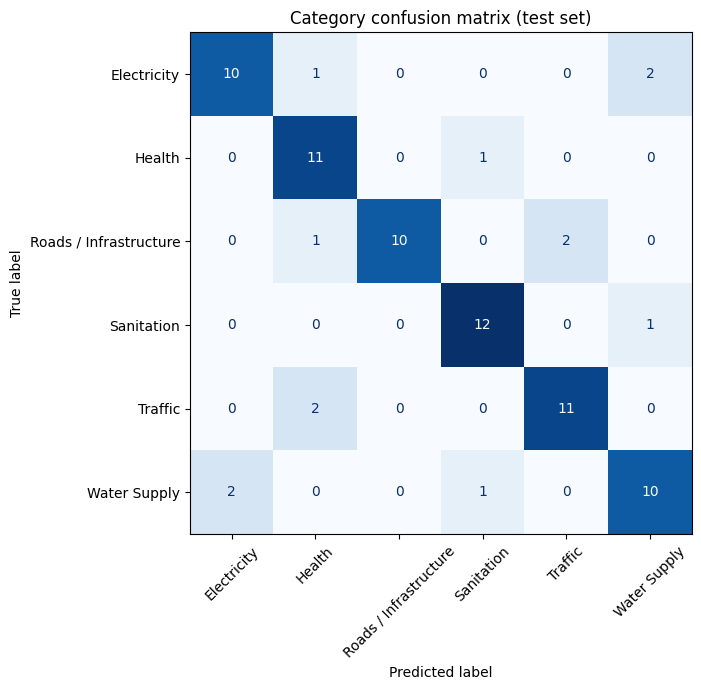

saved in: /content/drive/MyDrive/nlp_task_4/outputs


In [ ]:
import pandas as pd, numpy as np, joblib, os
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, make_union
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

BASE = "/content/drive/MyDrive/nlp_task_4"
P = f"{BASE}/data/processed"
OUT = f"{BASE}/outputs"
os.makedirs(OUT, exist_ok=True)

train = pd.read_csv(f"{P}/train.csv")
val   = pd.read_csv(f"{P}/val.csv")
test  = pd.read_csv(f"{P}/test.csv")
trval = pd.concat([train, val], ignore_index=True)   # model chunne ke liye (433)
print("train+val:", len(trval), "| test (abhi tak chhua nahi):", len(test))

word = lambda: TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
char = lambda: TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)
lr   = lambda: LogisticRegression(max_iter=2000, class_weight="balanced")

cands = {
    "word + LogReg (baseline)": lambda: Pipeline([("f", word()), ("c", lr())]),
    "char + LogReg":            lambda: Pipeline([("f", char()), ("c", lr())]),
    "word+char + LogReg":       lambda: Pipeline([("f", make_union(word(), char())), ("c", lr())]),
    "word+char + LinearSVC":    lambda: Pipeline([("f", make_union(word(), char())), ("c", LinearSVC(class_weight="balanced"))]),
}

# 1. 5-fold CV (sirf train+val par) se model chuno
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows, best = [], {}
for target in ["category", "sentiment", "priority"]:
    for name, make in cands.items():
        cv = cross_validate(make(), trval["text"], trval[target], cv=skf,
                            scoring=["accuracy", "f1_macro"])
        rows.append({"target": target, "model": name,
                     "cv_acc": round(cv["test_accuracy"].mean(), 3),
                     "cv_acc_std": round(cv["test_accuracy"].std(), 3),
                     "cv_macro_f1": round(cv["test_f1_macro"].mean(), 3)})
    sub = pd.DataFrame([r for r in rows if r["target"] == target])
    best[target] = sub.sort_values("cv_macro_f1", ascending=False).iloc[0]["model"]

cvres = pd.DataFrame(rows)
print(cvres.to_string(index=False))
cvres.to_csv(f"{OUT}/cv_results.csv", index=False)
print("\nChuna hua model:", best)

# 2. Test set par ek hi baar evaluation
test_rows, final_preds = [], {}
for target in ["category", "sentiment", "priority"]:
    for label, name in [("baseline", "word + LogReg (baseline)"), ("best", best[target])]:
        m = cands[name]().fit(trval["text"], trval[target])
        pred = m.predict(test["text"])
        test_rows.append({"target": target, "which": label, "model": name,
            "accuracy":  round(accuracy_score(test[target], pred), 3),
            "precision": round(precision_score(test[target], pred, average="macro", zero_division=0), 3),
            "recall":    round(recall_score(test[target], pred, average="macro", zero_division=0), 3),
            "macro_f1":  round(f1_score(test[target], pred, average="macro"), 3)})
        if label == "best":
            final_preds[target] = pred
        if target == "category" and label == "baseline":
            joblib.dump(m, f"{BASE}/models/baseline_model.pkl")

tres = pd.DataFrame(test_rows)
print("\n===== TEST RESULTS (77 samples) =====")
print(tres.to_string(index=False))
tres.to_csv(f"{OUT}/test_results.csv", index=False)

# 3. Category: classification report + confusion matrix
rep = classification_report(test["category"], final_preds["category"], zero_division=0)
print("\n===== CATEGORY: per-class report =====")
print(rep)
with open(f"{OUT}/classification_report.txt", "w") as f:
    f.write(f"Model: {best['category']}\nTest samples: {len(test)}\n\n{rep}")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test["category"], final_preds["category"],
                                        xticks_rotation=45, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Category confusion matrix (test set)")
plt.tight_layout()
plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150)
plt.show()
print("saved in:", OUT)

In [ ]:
import pandas as pd
from sklearn.model_selection import cross_val_predict, StratifiedKFold

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 250)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
targets = ["category", "sentiment", "priority"]

# 1. Final models (train+val par fit)
final = {t: cands[best[t]]().fit(trval["text"], trval[t]) for t in targets}

# 2. sample_predictions.csv (test set ke 25 samples)
sp = test.sample(25, random_state=7)[["text"] + targets].rename(
    columns={t: f"actual_{t}" for t in targets})
for t in targets:
    sp[f"pred_{t}"] = final[t].predict(sp["text"])
sp.to_csv(f"{OUT}/sample_predictions.csv", index=False)
print("sample predictions saved:", len(sp))

# 3. Category ki galtiyan: test ki saari + CV (out-of-fold) ki 12
pt = final["category"].predict(test["text"])
e_test = test.assign(predicted=pt, source="test")
e_test = e_test[e_test["category"] != e_test["predicted"]]

oof = cross_val_predict(cands[best["category"]](), trval["text"], trval["category"], cv=skf)
e_cv = trval.assign(predicted=oof, source="cv")
e_cv = e_cv[e_cv["category"] != e_cv["predicted"]]
e_cv = e_cv.sample(min(12, len(e_cv)), random_state=42)

err = pd.concat([e_test, e_cv], ignore_index=True)[["text", "category", "predicted", "source"]]
err = err.rename(columns={"category": "actual"})
err["error_type"] = ""
err["possible_reason"] = ""
err.to_csv(f"{OUT}/error_analysis.csv", index=False)

print("\nerror cases:", len(err))
print(err[["text", "actual", "predicted", "source"]].to_string())

sample predictions saved: 25

error cases: 25
                                                                        text                  actual               predicted source
0                       How can we report a leaking pipe on the main street?            Water Supply             Electricity   test
1       Deep trench for cable laying was not refilled properly and has sunk.  Roads / Infrastructure                  Health   test
2                       Nalkay se ganda pani aa raha hai, peena mushkil hai.            Water Supply              Sanitation   test
3             Rubbish is piled up near the water tank and spreading disease.              Sanitation            Water Supply   test
4                          The new meter was installed on the promised date.             Electricity            Water Supply   test
5             Filtration plant band hone ki wajah se log bimar ho rahe hain.            Water Supply             Electricity   test
6                        The o

In [ ]:
labels = [
 ("Few or rare keywords", "Neutral question with generic words; 'pipe' is rare in training data"),
 ("Multi-topic text", "Cable laying (electricity) and trench (road) in one sentence"),
 ("Roman Urdu / unseen words", "'nalkay' never seen in English training data; 'ganda' pulled it to Sanitation"),
 ("Multi-topic text", "Mentions rubbish, water tank and disease, so three categories overlap"),
 ("Positive wording hides topic", "Praise wording; 'meter' also appears in water complaints"),
 ("Roman Urdu / unseen words", "Roman Urdu text with no known topic words"),
 ("Positive wording hides topic", "Praise wording; 'challan' is rare in training data"),
 ("Ambiguous label", "Pedestrian bridge is both road infrastructure and traffic safety"),
 ("Misleading keyword", "'health workers' pushed it toward cleanliness-type words like 'street' and 'regularly'"),
 ("Few or rare keywords", "Neutral inspection request without strong electrical words"),
 ("Positive wording hides topic", "Praise wording; 'fixed quickly' is common across categories"),
 ("Few or rare keywords", "'receipts' and 'explanation' look like billing complaints, 'challan' is rare"),
 ("Ambiguous label", "Reflectors on a curve are road equipment as well as traffic safety"),
 ("Ambiguous label", "Streetlights are labeled both Roads and Electricity in the dataset"),
 ("Few or rare keywords", "Very short request; 'lineman' is rare"),
 ("Positive wording hides topic", "Praise wording; 'service' and 'on time' are generic"),
 ("Multi-topic text", "Toilets (sanitation) and lack of water (water supply) in one sentence"),
 ("Few or rare keywords", "Neutral maintenance notice with no electricity keyword"),
 ("Misleading keyword", "'outside our house' and 'repaired' are common in road complaints"),
 ("Misleading keyword", "'wheelchairs' appears in hospital complaints in the training data"),
 ("Positive wording hides topic", "Praise wording; 'safely tied up' is generic"),
 ("Misleading keyword", "'staff' and 'helpful' are common in Health praise samples"),
 ("Ambiguous label", "Streetlights on a road: Roads or Electricity"),
 ("Roman Urdu / unseen words", "'time table' appears mostly in Sanitation samples (garbage collection timetable)"),
 ("Roman Urdu / unseen words", "Mixed road and water words in Roman Urdu; 'guzarna' unseen"),
]
assert len(labels) == len(err), (len(labels), len(err))
err["error_type"] = [a for a, b in labels]
err["possible_reason"] = [b for a, b in labels]
err.to_csv(f"{OUT}/error_analysis.csv", index=False)
print(err["error_type"].value_counts())
print("saved error_analysis.csv with", len(err), "cases")

error_type
Few or rare keywords            5
Positive wording hides topic    5
Ambiguous label                 4
Roman Urdu / unseen words       4
Misleading keyword              4
Multi-topic text                3
Name: count, dtype: int64
saved error_analysis.csv with 25 cases


In [ ]:
!pip -q install sentence-transformers

import pandas as pd, numpy as np, joblib
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, f1_score

BASE = "/content/drive/MyDrive/nlp_task_4"
P, OUT = f"{BASE}/data/processed", f"{BASE}/outputs"
train = pd.read_csv(f"{P}/train.csv"); val = pd.read_csv(f"{P}/val.csv"); test = pd.read_csv(f"{P}/test.csv")
trval = pd.concat([train, val], ignore_index=True)
targets = ["category", "sentiment", "priority"]

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
st = SentenceTransformer(MODEL_NAME)
enc = lambda texts: st.encode(list(texts), batch_size=32, normalize_embeddings=True, show_progress_bar=False)
X_trval, X_test = enc(trval["text"]), enc(test["text"])
print("embedding shape:", X_trval.shape)

# ---------- A. Zero-shot: category ki tashreeh se similarity ----------
desc = {
 "Roads / Infrastructure": "road, pothole, bridge, footpath, street construction and infrastructure damage",
 "Water Supply": "drinking water supply, pipeline, tap, tube well and water shortage",
 "Electricity": "electricity, power outage, transformer, electric wires, voltage and load shedding",
 "Sanitation": "garbage, waste collection, sewer, drains and cleanliness",
 "Health": "hospital, doctor, medicines, clinic, vaccination and health services",
 "Traffic": "traffic jams, traffic signals, driving rules, parking, accidents and traffic police",
}
names = list(desc)
D = enc(desc.values())
zs = lambda X: np.array(names)[(X @ D.T).argmax(1)]   # training nahi, isliye trval par bhi fair
rows = []
for nm, X, df_ in [("trval (433)", X_trval, trval), ("test (77)", X_test, test)]:
    p = zs(X)
    rows.append({"method": "Zero-shot (embedding similarity)", "target": "category", "data": nm,
                 "accuracy": round(accuracy_score(df_["category"], p), 3),
                 "macro_f1": round(f1_score(df_["category"], p, average="macro"), 3)})

# ---------- B. Embeddings + LogisticRegression ----------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mk = lambda: LogisticRegression(max_iter=3000, class_weight="balanced", C=10)
clfs = {}
for t in targets:
    cv = cross_validate(mk(), X_trval, trval[t], cv=skf, scoring=["accuracy", "f1_macro"])
    clf = mk().fit(X_trval, trval[t]); clfs[t] = clf
    p = clf.predict(X_test)
    rows.append({"method": "Embeddings + LogReg", "target": t, "data": "CV on trval",
                 "accuracy": round(cv["test_accuracy"].mean(), 3), "macro_f1": round(cv["test_f1_macro"].mean(), 3)})
    rows.append({"method": "Embeddings + LogReg", "target": t, "data": "test (77)",
                 "accuracy": round(accuracy_score(test[t], p), 3),
                 "macro_f1": round(f1_score(test[t], p, average="macro"), 3)})

res = pd.DataFrame(rows)
res.to_csv(f"{OUT}/hf_results.csv", index=False)
print(res.to_string(index=False))

# ---------- Pichle TF-IDF models se muqabla (CV macro F1) ----------
cvold = pd.read_csv(f"{OUT}/cv_results.csv")
print("\nBest TF-IDF model (CV macro F1):")
print(cvold.sort_values("cv_macro_f1", ascending=False).groupby("target").head(1)[["target", "model", "cv_macro_f1"]].to_string(index=False))

# ---------- Roman Urdu check ----------
joblib.dump(clfs["category"], f"{BASE}/models/embedding_category_model.pkl")
tests = ["pani nhi arha", "bijli band ha",
         "hamare area ki road bohat kharab hai aur pani jama hota hai",
         "Nalkay se ganda pani aa raha hai, peena mushkil hai."]
pr = clfs["category"].predict_proba(enc(tests))
print("\nRoman Urdu check:")
for s, row in zip(tests, pr):
    print(f"{s!r:75} -> {clfs['category'].classes_[row.argmax()]} ({row.max():.2f})")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

embedding shape: (433, 384)
                          method    target        data  accuracy  macro_f1
Zero-shot (embedding similarity)  category trval (433)     0.783     0.783
Zero-shot (embedding similarity)  category   test (77)     0.857     0.862
             Embeddings + LogReg  category CV on trval     0.855     0.853
             Embeddings + LogReg  category   test (77)     0.792     0.791
             Embeddings + LogReg sentiment CV on trval     0.926     0.907
             Embeddings + LogReg sentiment   test (77)     0.883     0.847
             Embeddings + LogReg  priority CV on trval     0.584     0.551
             Embeddings + LogReg  priority   test (77)     0.545     0.462

Best TF-IDF model (CV macro F1):
   target                    model  cv_macro_f1
sentiment word + LogReg (baseline)        0.873
 category    word+char + LinearSVC        0.842
 priority            char + LogReg        0.566

Roman Urdu check:
'pani nhi arha'                                     

In [ ]:
import re, joblib, numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

BASE = "/content/drive/MyDrive/nlp_task_4"
OUT = f"{BASE}/outputs"

if "st" not in globals():
    from sentence_transformers import SentenceTransformer
    st = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
enc = lambda texts: st.encode(list(texts), batch_size=32, normalize_embeddings=True, show_progress_bar=False)

# 1. Final models: sab 510 samples par (evaluation pehle ho chuki hai)
df = pd.read_csv(f"{BASE}/data/processed/feedback_clean.csv")
X_all = enc(df["text"])
lr_emb = lambda: LogisticRegression(max_iter=3000, class_weight="balanced", C=10)
final = {
    "category":  lr_emb().fit(X_all, df["category"]),
    "sentiment": lr_emb().fit(X_all, df["sentiment"]),
    "priority":  Pipeline([("f", TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)),
                           ("c", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(df["text"], df["priority"]),
}
for t, m in final.items():
    joblib.dump(m, f"{BASE}/models/{t}_model.pkl")
print("final models saved")

def predict(target, text):
    m = final[target]
    X = [text] if target == "priority" else enc([text])
    p = m.predict_proba(X)[0]
    return m.classes_[p.argmax()], float(p.max())

# 2. Keywords: candidate words/phrases ko text ke embedding se rank karte hain (KeyBERT jaisa idea)
STOP = set("""a an the is are was were be been being am of in on at to for from by with and or but not no nor so than too
very this that these those it its our your their my we you they he she i me us them has have had do does did will would
can could should may might shall please kindly also just still yet again every each any some there here near about after
before during over under into out up down off as if when while where which who what how why all get gets got given
hai hain ho hota hoti hote ka ki ke ko se mein par aur ya bhi to ye wo yeh woh hamare hamari hamara apne apna kar kya
kyun kyunke jo jab tak nhi nahi na bohat bahut hum tum aap ab abhi ek hay ha raha rahi rahe gaya gayi gaye dein den""".split())

def keywords(text, top_n=4):
    toks = re.findall(r"[a-zA-Z']+", text.lower())
    cands = set()
    for n in (1, 2):
        for i in range(len(toks) - n + 1):
            g = toks[i:i + n]
            if any(len(w) < 3 for w in g) or g[0] in STOP or g[-1] in STOP:
                continue
            cands.add(" ".join(g))
    if not cands:
        return []
    cands = sorted(cands)
    sims = (enc(cands) @ enc([text]).T).ravel()
    chosen, covered = [], set()
    for idx in sims.argsort()[::-1]:
        c = cands[idx]; ws = set(c.split())
        if ws <= covered:
            continue
        chosen.append(c); covered |= ws
        if len(chosen) == top_n:
            break
    return chosen

# 3. Suggested department / action (example mapping, official nahi)
DEPT = {
 "Roads / Infrastructure": ("Municipal / Infrastructure (Works and Services)", "Inspect and repair the reported road or infrastructure issue"),
 "Water Supply": ("Water and Sanitation Authority / Public Health Engineering", "Check the water line or supply schedule and restore service"),
 "Electricity": ("Electricity Distribution Company / Power Department", "Send a technical team to inspect the fault"),
 "Sanitation": ("Municipal Sanitation / Solid Waste Management", "Schedule cleaning, garbage collection or sewer clearing"),
 "Health": ("District Health Authority / Health Department", "Review the service problem with the health facility"),
 "Traffic": ("Traffic Police / Transport Department", "Review signals, traffic management or enforcement at the location"),
}

def analyze_feedback(text, review_threshold=0.35):
    text = re.sub(r"\s+", " ", text).strip()
    cat, cat_c = predict("category", text)
    sent, sent_c = predict("sentiment", text)
    prio, prio_c = predict("priority", text)
    kws = keywords(text)
    dept, action = DEPT[cat]
    kw_txt = ", ".join(kws) if kws else "n/a"
    if sent == "Positive":
        summary = f"Citizen shares positive feedback about {cat} services ({kw_txt})."
        action = "Acknowledge the feedback and share it with the team"
    elif sent == "Neutral":
        summary = f"Citizen makes a request or enquiry related to {cat} ({kw_txt})."
    else:
        summary = f"Citizen reports a {cat} problem ({kw_txt})."
        if prio in ("High", "Urgent"):
            action = "Priority handling: " + action
    flags = []
    if cat_c < review_threshold: flags.append("low category confidence")
    if prio == "Urgent": flags.append("urgent priority")
    return {"text": text, "category": cat, "category_score": round(cat_c, 2),
            "sentiment": sent, "sentiment_score": round(sent_c, 2),
            "priority": prio, "priority_score": round(prio_c, 2),
            "keywords": kws, "suggested_department": dept, "summary": summary,
            "suggested_action": action,
            "needs_manual_review": bool(flags), "review_reason": ", ".join(flags)}

def show(r):
    print("-" * 70)
    print("Input     :", r["text"])
    print(f"Category  : {r['category']} ({r['category_score']})")
    print(f"Sentiment : {r['sentiment']} ({r['sentiment_score']})")
    print(f"Priority  : {r['priority']} ({r['priority_score']})")
    print("Keywords  :", ", ".join(r["keywords"]))
    print("Department:", r["suggested_department"])
    print("Summary   :", r["summary"])
    print("Action    :", r["suggested_action"])
    print("Review    :", ("YES (" + r["review_reason"] + ")") if r["needs_manual_review"] else "no")

# 4. Test
samples = [
 "The road in our area has been broken for months and rainwater collects every day. Please fix it urgently.",
 "The hospital staff was helpful but the waiting time was too long.",
 "There is no water supply in our area for three days.",
 "The new garbage truck comes on time.",
 "hamare area ki road bohat kharab hai aur pani jama hota hai",
 "bijli band ha",
]
results = [analyze_feedback(s) for s in samples]
for r in results:
    show(r)
pd.DataFrame(results).to_csv(f"{OUT}/sample_insights.csv", index=False)
print("\nsaved: outputs/sample_insights.csv")

final models saved
----------------------------------------------------------------------
Input     : The road in our area has been broken for months and rainwater collects every day. Please fix it urgently.
Category  : Roads / Infrastructure (0.93)
Sentiment : Negative (0.59)
Priority  : High (0.42)
Keywords  : rainwater, road, rainwater collects, broken
Department: Municipal / Infrastructure (Works and Services)
Summary   : Citizen reports a Roads / Infrastructure problem (rainwater, road, rainwater collects, broken).
Action    : Priority handling: Inspect and repair the reported road or infrastructure issue
Review    : no
----------------------------------------------------------------------
Input     : The hospital staff was helpful but the waiting time was too long.
Category  : Health (1.0)
Sentiment : Neutral (0.53)
Priority  : Medium (0.43)
Keywords  : hospital staff, waiting time, long, helpful
Department: District Health Authority / Health Department
Summary   : Citizen makes 

In [ ]:
STOP |= {"area"}

ROMAN_HINTS = {"hai","hain","nahi","nhi","bohat","aur","hamare","hamari","mein","bijli","pani",
               "sarak","gali","kachra","safai","ganda","nalkay","kharab","mushkil","dawai",
               "mohalle","ilaqe","raha","rahi","aya","ha"}

def analyze_feedback(text, review_threshold=0.45):
    text = re.sub(r"\s+", " ", text).strip()
    cat, cat_c = predict("category", text)
    sent, sent_c = predict("sentiment", text)
    prio, prio_c = predict("priority", text)
    kws = keywords(text)
    dept, action = DEPT[cat]
    kw_txt = ", ".join(kws) if kws else "n/a"
    if sent == "Positive":
        summary = f"Citizen shares positive feedback about {cat} services ({kw_txt})."
        action = "Acknowledge the feedback and share it with the team"
    elif sent == "Neutral":
        summary = f"Citizen shares a neutral or mixed comment or request about {cat} ({kw_txt})."
    else:
        summary = f"Citizen reports a {cat} problem ({kw_txt})."
        if prio in ("High", "Urgent"):
            action = "Priority handling: " + action
    flags = []
    if cat_c < review_threshold: flags.append("low category confidence")
    if prio == "Urgent": flags.append("urgent priority")
    if set(re.findall(r"[a-z]+", text.lower())) & ROMAN_HINTS:
        flags.append("Roman Urdu input (model trained mostly on English)")
    return {"text": text, "category": cat, "category_score": round(cat_c, 2),
            "sentiment": sent, "sentiment_score": round(sent_c, 2),
            "priority": prio, "priority_score": round(prio_c, 2),
            "keywords": kws, "suggested_department": dept, "summary": summary,
            "suggested_action": action,
            "needs_manual_review": bool(flags), "review_reason": ", ".join(flags)}

results = [analyze_feedback(s) for s in samples]
for r in results:
    show(r)
pd.DataFrame(results).to_csv(f"{OUT}/sample_insights.csv", index=False)
print("\nsaved: outputs/sample_insights.csv")

----------------------------------------------------------------------
Input     : The road in our area has been broken for months and rainwater collects every day. Please fix it urgently.
Category  : Roads / Infrastructure (0.93)
Sentiment : Negative (0.59)
Priority  : High (0.42)
Keywords  : rainwater, road, rainwater collects, broken
Department: Municipal / Infrastructure (Works and Services)
Summary   : Citizen reports a Roads / Infrastructure problem (rainwater, road, rainwater collects, broken).
Action    : Priority handling: Inspect and repair the reported road or infrastructure issue
Review    : no
----------------------------------------------------------------------
Input     : The hospital staff was helpful but the waiting time was too long.
Category  : Health (1.0)
Sentiment : Neutral (0.53)
Priority  : Medium (0.43)
Keywords  : hospital staff, waiting time, long, helpful
Department: District Health Authority / Health Department
Summary   : Citizen shares a neutral or mixed

In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/nlp_task_4/app"))
print(os.listdir("/content/drive/MyDrive/nlp_task_4/models"))

['utils.py', 'streamlit_app.py', 'demo.py']
['category_model.joblib', 'sentiment_model.joblib', 'priority_model.joblib', 'label_encoder.pkl', 'baseline_model.pkl', 'embedding_category_model.pkl', 'category_model.pkl', 'sentiment_model.pkl', 'priority_model.pkl']


In [ ]:
!pip -q install sentence-transformers
!python /content/drive/MyDrive/nlp_task_4/app/demo.py "There is no water supply in our area for three days."

Loading weights: 100% 199/199 [00:00<00:00, 5321.97it/s]
----------------------------------------------------------------------
Input     : There is no water supply in our area for three days.
Category  : Water Supply (0.96)
Sentiment : Negative (1.0)
Priority  : High (0.56)  [indicative only]
Keywords  : water supply, three days
Department: Water and Sanitation Authority / Public Health Engineering
Summary   : Citizen reports a Water Supply problem (water supply, three days).
Action    : Priority handling: Check the water line or supply schedule and restore service
Review    : no
----------------------------------------------------------------------


In [ ]:
%run /content/drive/MyDrive/nlp_task_4/app/demo.py

CitizenSense CLI demo (type 'quit' to exit)

Enter feedback text: The road in our area has been broken for months and rainwater collects every day. Please fix it urgently.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

----------------------------------------------------------------------
Input     : The road in our area has been broken for months and rainwater collects every day. Please fix it urgently.
Category  : Roads / Infrastructure (0.93)
Sentiment : Negative (0.59)
Priority  : High (0.42)  [indicative only]
Keywords  : rainwater, road, rainwater collects, broken
Department: Municipal / Infrastructure (Works and Services)
Summary   : Citizen reports a Roads / Infrastructure problem (rainwater, road, rainwater collects, broken).
Action    : Priority handling: Inspect and repair the reported road or infrastructure issue
Review    : no
----------------------------------------------------------------------

Enter feedback text: light band ha
----------------------------------------------------------------------
Input     : light band ha
Category  : Electricity (0.9)
Sentiment : Negative (0.58)
Priority  : Medium (0.32)  [indicative only]
Keywords  : light band
Department: Electricity Distribution 

<Figure size 640x480 with 0 Axes>

In [ ]:
import sys, pandas as pd
BASE = "/content/drive/MyDrive/nlp_task_4"
sys.path.insert(0, f"{BASE}/app")
from utils import analyze_feedback

test = pd.read_csv(f"{BASE}/data/processed/test.csv")
rows = []

for _, r in test.sample(22, random_state=11).iterrows():
    a = analyze_feedback(r["text"])
    rows.append({"text": r["text"], "source": "test set (seen by final model)",
                 "actual_category": r["category"], "pred_category": a["category"],
                 "category_score": a["category_score"],
                 "actual_sentiment": r["sentiment"], "pred_sentiment": a["sentiment"],
                 "actual_priority": r["priority"], "pred_priority": a["priority"],
                 "keywords": ", ".join(a["keywords"]), "suggested_department": a["suggested_department"],
                 "summary": a["summary"], "needs_manual_review": a["needs_manual_review"]})

new = [
 "Street lights on the highway have been off since last Monday.",
 "The doctor at the clinic did not give proper medicine to my son.",
 "Cars are parked on both sides of the road and traffic does not move.",
 "Please clean the drain in front of the mosque before Eid.",
 "Water coming from the tap has a strange smell.",
 "The electricity bill this month is much higher than usual.",
 "kachra uthane wali gaari nahi aa rahi",
 "hospital mein doctor nahi tha",
]
for s in new:
    a = analyze_feedback(s)
    rows.append({"text": s, "source": "new sentence (not in dataset)",
                 "actual_category": "", "pred_category": a["category"], "category_score": a["category_score"],
                 "actual_sentiment": "", "pred_sentiment": a["sentiment"],
                 "actual_priority": "", "pred_priority": a["priority"],
                 "keywords": ", ".join(a["keywords"]), "suggested_department": a["suggested_department"],
                 "summary": a["summary"], "needs_manual_review": a["needs_manual_review"]})

sp = pd.DataFrame(rows)
sp.to_csv(f"{BASE}/outputs/sample_predictions.csv", index=False)
print("saved:", len(sp), "predictions")
pd.set_option("display.width", 250, "display.max_colwidth", 70)
print(sp[["text", "pred_category", "category_score", "pred_sentiment", "pred_priority", "needs_manual_review"]].to_string())

saved: 30 predictions
                                                                             text           pred_category  category_score pred_sentiment pred_priority  needs_manual_review
0                                           Hospital is too far from our village.                  Health            0.95       Negative        Medium                False
1                           Pani ki supply ab bohat behtar ho gayi hai, shukriya.            Water Supply            0.43       Positive           Low                 True
2                                       Water from the tap smells like chemicals.            Water Supply            0.96       Negative          High                False
3               The electricity complaint office is closed during official hours.             Electricity            0.95       Negative           Low                False
4              Uneven patchwork on the road makes bike riding very uncomfortable.  Roads / Infrastructure            0

accuracy: 0.792 | macro F1: 0.791
                        precision    recall  f1-score   support

           Electricity       0.71      0.77      0.74        13
                Health       0.86      1.00      0.92        12
Roads / Infrastructure       0.67      0.62      0.64        13
            Sanitation       0.86      0.92      0.89        13
               Traffic       0.77      0.77      0.77        13
          Water Supply       0.90      0.69      0.78        13

              accuracy                           0.79        77
             macro avg       0.79      0.79      0.79        77
          weighted avg       0.79      0.79      0.79        77



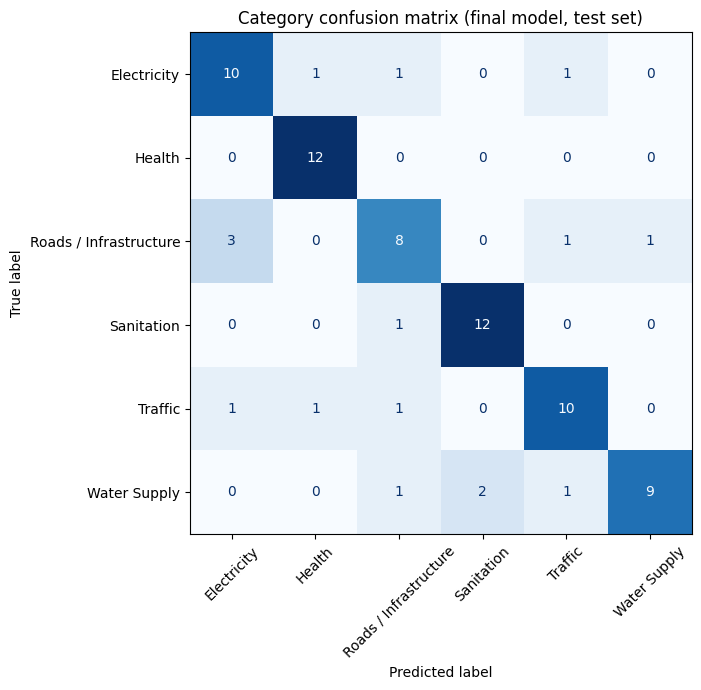

In [ ]:
import sys, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

BASE = "/content/drive/MyDrive/nlp_task_4"
sys.path.insert(0, f"{BASE}/app")
from utils import encode

P, OUT = f"{BASE}/data/processed", f"{BASE}/outputs"
trval = pd.concat([pd.read_csv(f"{P}/train.csv"), pd.read_csv(f"{P}/val.csv")], ignore_index=True)
test = pd.read_csv(f"{P}/test.csv")

clf = LogisticRegression(max_iter=3000, class_weight="balanced", C=10).fit(encode(trval["text"]), trval["category"])
pred = clf.predict(encode(test["text"]))
print("accuracy:", round(accuracy_score(test["category"], pred), 3),
      "| macro F1:", round(f1_score(test["category"], pred, average="macro"), 3))

rep = classification_report(test["category"], pred, zero_division=0)
print(rep)
with open(f"{OUT}/classification_report.txt", "w") as f:
    f.write("Final category model: multilingual sentence embeddings + Logistic Regression\n"
            f"Trained on train+val ({len(trval)}), evaluated once on test ({len(test)})\n\n{rep}")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test["category"], pred, xticks_rotation=45, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Category confusion matrix (final model, test set)")
plt.tight_layout()
plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
import os
OUT = f"{BASE}/outputs"
old, bak = f"{OUT}/error_analysis.csv", f"{OUT}/error_analysis_tfidf_model.csv"
if os.path.exists(old) and not os.path.exists(bak):
    os.rename(old, bak)

e = test.assign(predicted=pred)
e = e[e["category"] != e["predicted"]][["text", "category", "predicted"]]
e = e.rename(columns={"category": "actual"}).reset_index(drop=True)
e.to_csv(f"{OUT}/error_analysis_raw.csv", index=False)

pd.set_option("display.width", 250, "display.max_colwidth", 90)
print(len(e), "errors")
print(e.to_string())

16 errors
                                                                          text                  actual               predicted
0         Deep trench for cable laying was not refilled properly and has sunk.  Roads / Infrastructure             Electricity
1                Street lights on the main road have not worked for two weeks.  Roads / Infrastructure             Electricity
2                         Nalkay se ganda pani aa raha hai, peena mushkil hai.            Water Supply              Sanitation
3                              Bijli ka masla hal ho gaya hai, bohat shukriya.             Electricity  Roads / Infrastructure
4                     Bijli ka bill bohat zyada aya hai, meter check karwayen.             Electricity                 Traffic
5                 Public tap ki tonti toot gayi hai aur pani zaya ho raha hai.            Water Supply                 Traffic
6               Filtration plant band hone ki wajah se log bimar ho rahe hain.            Water Suppl

In [ ]:
import os
OUT = f"{BASE}/outputs"
old, bak = f"{OUT}/error_analysis.csv", f"{OUT}/error_analysis_tfidf_model.csv"
if os.path.exists(old) and not os.path.exists(bak):
    os.rename(old, bak)

e = test.assign(predicted=pred)
e = e[e["category"] != e["predicted"]][["text", "category", "predicted"]]
e = e.rename(columns={"category": "actual"}).reset_index(drop=True)
e.to_csv(f"{OUT}/error_analysis_raw.csv", index=False)

pd.set_option("display.width", 250, "display.max_colwidth", 90)
print(len(e), "errors")
print(e.to_string())

16 errors
                                                                          text                  actual               predicted
0         Deep trench for cable laying was not refilled properly and has sunk.  Roads / Infrastructure             Electricity
1                Street lights on the main road have not worked for two weeks.  Roads / Infrastructure             Electricity
2                         Nalkay se ganda pani aa raha hai, peena mushkil hai.            Water Supply              Sanitation
3                              Bijli ka masla hal ho gaya hai, bohat shukriya.             Electricity  Roads / Infrastructure
4                     Bijli ka bill bohat zyada aya hai, meter check karwayen.             Electricity                 Traffic
5                 Public tap ki tonti toot gayi hai aur pani zaya ho raha hai.            Water Supply                 Traffic
6               Filtration plant band hone ki wajah se log bimar ho rahe hain.            Water Suppl

In [ ]:
types = [
 "Overlapping categories",
 "Label ambiguity",
 "Roman Urdu",
 "Roman Urdu, positive feedback",
 "Roman Urdu",
 "Roman Urdu",
 "Roman Urdu, overlapping categories",
 "Unseen topic",
 "Inconsistent labeling",
 "Label ambiguity",
 "Short text, few keywords",
 "Roman Urdu, positive feedback",
 "Overlapping categories",
 "Multi-issue text",
 "Unseen topic",
 "Roman Urdu, overlapping categories",
]

reasons = [
 "Cable trench is electrical work but damage is to the road.",
 "Street lights can be Roads or Electricity; guideline unclear.",
 "Dirty water sits between Water Supply and Sanitation.",
 "Thank-you message with no strong category word.",
 "Roman Urdu words for bill and meter are weakly understood.",
 "Rare Roman Urdu words (tonti, zaya) not linked to water.",
 "Health effect of a water plant; three categories overlap.",
 "Few training samples about challan; positive tone.",
 "Pedestrian bridge can be Roads or Traffic; labels inconsistent.",
 "Same street-light ambiguity: Roads vs Electricity.",
 "Very short text; resembles health-worker visit samples.",
 "Positive Roman Urdu text with no complaint keywords.",
 "Zebra crossing is road safety; Roads and Traffic overlap.",
 "Drainage, road and standing water in one positive sentence.",
 "Few challan examples; resembles billing complaints.",
 "Standing drain water resembles road waterlogging samples.",
]

assert len(e) == 16, f"expected 16 rows, got {len(e)}"
assert len(types) == 16 and len(reasons) == 16

final = pd.DataFrame({
    "Text Sample": e["text"],
    "Actual Label": e["actual"],
    "Predicted Label": e["predicted"],
    "Error Type": types,
    "Possible Reason": reasons,
})
final.to_csv(f"{OUT}/error_analysis.csv", index=False)
print(final.shape)
print(final["Error Type"].value_counts())

(16, 5)
Error Type
Roman Urdu                            3
Overlapping categories                2
Label ambiguity                       2
Roman Urdu, positive feedback         2
Roman Urdu, overlapping categories    2
Unseen topic                          2
Inconsistent labeling                 1
Short text, few keywords              1
Multi-issue text                      1
Name: count, dtype: int64


In [ ]:
import os

BASE = "/content/drive/MyDrive/nlp_task_4"
for folder in ["data/raw", "data/processed", "models", "outputs", "app", "screenshots", "report", "notebooks"]:
    path = f"{BASE}/{folder}"
    files = sorted(os.listdir(path)) if os.path.exists(path) else ["(folder missing)"]
    print(f"\n{folder}/")
    for f in files:
        print("   ", f)

for f in ["README.md", "requirements.txt"]:
    print(f, "->", "found" if os.path.exists(f"{BASE}/{f}") else "missing")


data/raw/
    feedback_extra_part3.csv
    feedback_manual_extra.csv
    feedback_raw.csv

data/processed/
    cv_results.csv
    feedback_clean.csv
    test.csv
    train.csv
    val.csv

models/
    baseline_model.pkl
    category_model.joblib
    category_model.pkl
    embedding_category_model.pkl
    label_encoder.pkl
    priority_model.joblib
    priority_model.pkl
    sentiment_model.joblib
    sentiment_model.pkl

outputs/
    classification_report.txt
    confusion_matrix.png
    cv_results.csv
    error_analysis.csv
    error_analysis_raw.csv
    error_analysis_tfidf_model.csv
    hf_results.csv
    sample_insights.csv
    sample_predictions.csv
    test_results.csv

app/
    __pycache__
    demo.py
    streamlit_app.py
    utils.py

screenshots/
    demo_input.png
    demo_output.png

report/

notebooks/
README.md -> missing
requirements.txt -> found


In [ ]:
import pandas as pd, os

BASE = "/content/drive/MyDrive/nlp_task_4"
P = f"{BASE}/data/processed"

clean = pd.read_csv(f"{P}/feedback_clean.csv")
print("clean:", clean.shape, "| columns:", list(clean.columns))
print(clean["category"].value_counts(), "\n")

for n in ["train", "val", "test"]:
    print(n, pd.read_csv(f"{P}/{n}.csv").shape)

print("\nlabels.csv exists:", os.path.exists(f"{BASE}/data/labels.csv"))
if "source" in clean.columns:
    print(clean["source"].value_counts())

O = f"{BASE}/outputs"
for f in ["sample_predictions.csv", "sample_insights.csv", "hf_results.csv", "cv_results.csv"]:
    d = pd.read_csv(f"{O}/{f}")
    print(f"\n=== {f} {d.shape} ===")
    print(d.head(3).to_string())

clean: (510, 7) | columns: ['text', 'category', 'sentiment', 'priority', 'category_id', 'sentiment_id', 'priority_id']
category
Roads / Infrastructure    85
Water Supply              85
Electricity               85
Sanitation                85
Health                    85
Traffic                   85
Name: count, dtype: int64 

train (357, 7)
val (76, 7)
test (77, 7)

labels.csv exists: True

=== sample_predictions.csv (30, 13) ===
                                                    text                          source actual_category pred_category  category_score actual_sentiment pred_sentiment actual_priority pred_priority                                        keywords                                        suggested_department                                                                                         summary  needs_manual_review
0                  Hospital is too far from our village.  test set (seen by final model)          Health        Health            0.95        

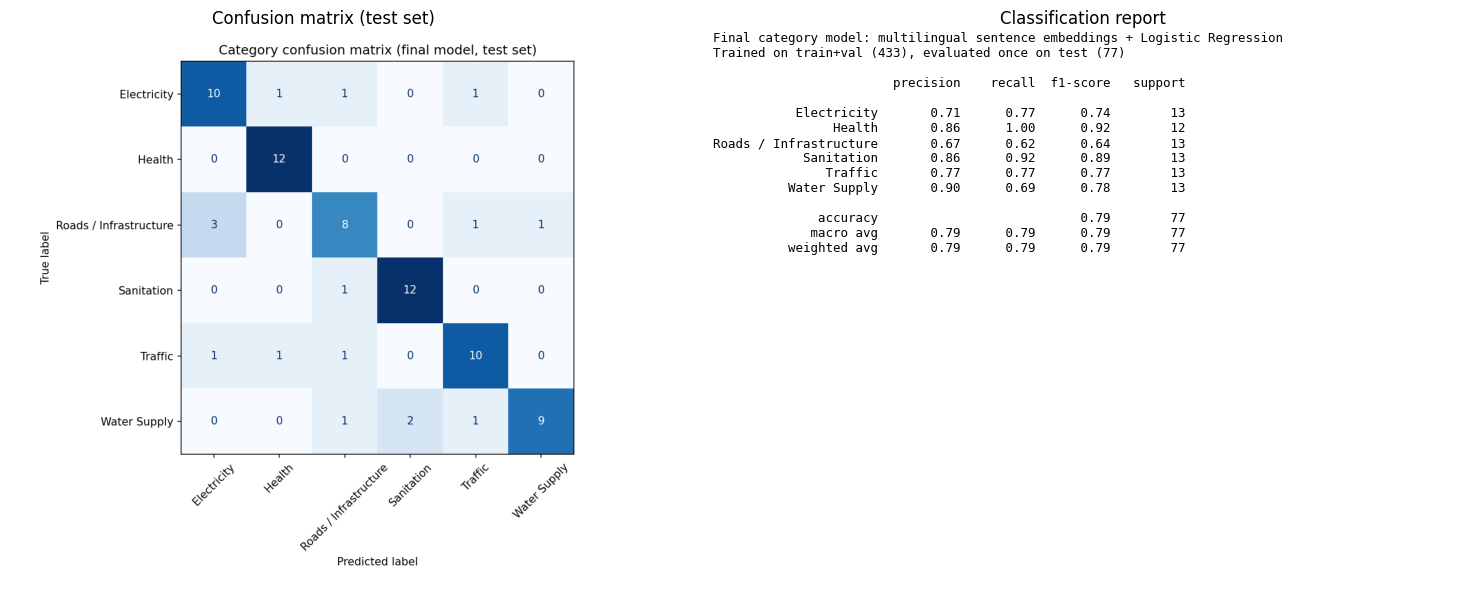

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

BASE = "/content/drive/MyDrive/nlp_task_4"
img = mpimg.imread(f"{BASE}/outputs/confusion_matrix.png")
txt = open(f"{BASE}/outputs/classification_report.txt").read()

fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].imshow(img)
ax[0].axis("off")
ax[0].set_title("Confusion matrix (test set)")
ax[1].axis("off")
ax[1].text(0, 1, txt, family="monospace", fontsize=9, va="top")
ax[1].set_title("Classification report")
plt.tight_layout()
plt.savefig(f"{BASE}/screenshots/evaluation_results.png", dpi=150, bbox_inches="tight")
plt.show()